# Relatório de métricas do YOLOv8-seg

Este relatório analisa o treinamento `teste02_dataset_model-2`, realizado com YOLOv8n-seg por 50 épocas. O modelo usa uma única classe (`lixo`) e foi treinado com imagens do `dataset_model`, convertidas para o formato YOLO-seg. O split contém 1.047 imagens de treino após augmentação e 63 imagens originais de validação; 9 amostras de treino têm rótulo vazio e são tratadas como exemplos negativos.

A augmentação foi aplicada somente ao treino: espelhamento horizontal, rotações de -10° e +10°, e clareamento seletivo de imagens escuras. A validação permaneceu sem augmentação. O relatório lê `results.csv`, compara as métricas ao longo das épocas e reavalia `best.pt` no split `val` para métricas gerais e por classe. Métricas de caixas (B) medem localização; métricas de máscaras (M) medem segmentação.

**Interpretação:** precisão mede a proporção de previsões corretas; recall mede a proporção de objetos reais encontrados. mAP@50 usa IoU 0,50; mAP@50–95 agrega limiares IoU de 0,50 a 0,95. Como há uma única classe, as métricas por classe se referem somente a `lixo`. Não há uma acurácia convencional apropriada como métrica principal para esta tarefa.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

PASTA_PROJETO = Path.cwd()
PASTA_EXECUCAO = PASTA_PROJETO / "runs" / "segment" / "teste02_dataset_model-2"
ARQUIVO_HISTORICO = PASTA_EXECUCAO / "results.csv"
ARQUIVO_BEST = PASTA_EXECUCAO / "weights" / "best.pt"
ARQUIVO_DATASET = PASTA_PROJETO / "dataset_model_yolo" / "dataset.yaml"

for caminho in (ARQUIVO_HISTORICO, ARQUIVO_BEST, ARQUIVO_DATASET):
    if not caminho.is_file():
        raise FileNotFoundError(f"Artefato do treinamento nao encontrado: {caminho}")

historico = pd.read_csv(ARQUIVO_HISTORICO)
historico.columns = historico.columns.str.strip()
print(f"Execucao analisada: {PASTA_EXECUCAO.name}")
print(f"Epocas registradas: {len(historico)}")
print(f"Pesos avaliados: {ARQUIVO_BEST}")
print(f"Dataset avaliado: {ARQUIVO_DATASET}")

Execucao analisada: teste02_dataset_model-2
Epocas registradas: 50
Pesos avaliados: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\weights\best.pt
Dataset avaliado: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo\dataset.yaml


,Melhor valor no histórico,Época do melhor valor,Valor na última época
Métrica,,,
Precisão caixas,0.8136,13,0.7966
Recall caixas,0.6918,31,0.6027
mAP50 caixas,0.6929,36,0.6640
mAP50-95 caixas,0.4770,45,0.4682
Precisão máscaras,0.8476,13,0.7871
Recall máscaras,0.6712,31,0.5959
mAP50 máscaras,0.6760,35,0.6420
mAP50-95 máscaras,0.4338,40,0.4140


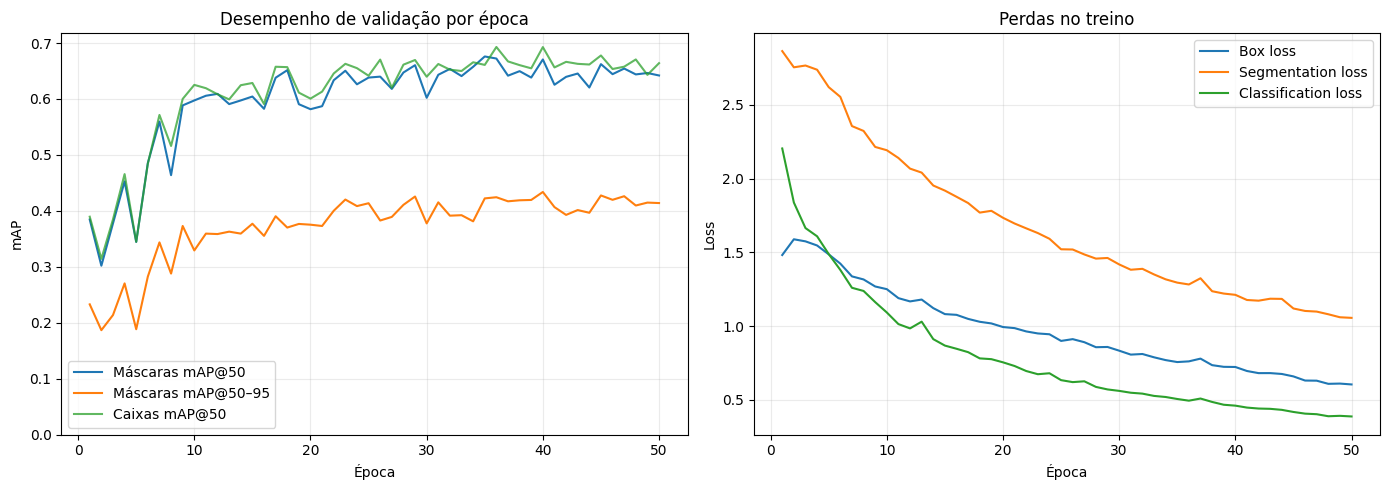

In [2]:
colunas_historico = {
    "Precisão caixas": "metrics/precision(B)",
    "Recall caixas": "metrics/recall(B)",
    "mAP50 caixas": "metrics/mAP50(B)",
    "mAP50-95 caixas": "metrics/mAP50-95(B)",
    "Precisão máscaras": "metrics/precision(M)",
    "Recall máscaras": "metrics/recall(M)",
    "mAP50 máscaras": "metrics/mAP50(M)",
    "mAP50-95 máscaras": "metrics/mAP50-95(M)",
}

colunas_ausentes = [coluna for coluna in colunas_historico.values() if coluna not in historico]
if colunas_ausentes:
    raise KeyError(f"Colunas esperadas não encontradas em results.csv: {colunas_ausentes}")

linha_final = historico.iloc[-1]
linhas_resumo = []
for nome_metrica, coluna in colunas_historico.items():
    indice_melhor = historico[coluna].idxmax()
    linhas_resumo.append(
        {
            "Métrica": nome_metrica,
            "Melhor valor no histórico": historico.loc[indice_melhor, coluna],
            "Época do melhor valor": int(historico.loc[indice_melhor, "epoch"]),
            "Valor na última época": linha_final[coluna],
        }
    )

resumo_historico = pd.DataFrame(linhas_resumo).set_index("Métrica")
display(resumo_historico.style.format({
    "Melhor valor no histórico": "{:.4f}",
    "Valor na última época": "{:.4f}",
}))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(historico["epoch"], historico["metrics/mAP50(M)"], label="Máscaras mAP@50")
eixos[0].plot(historico["epoch"], historico["metrics/mAP50-95(M)"], label="Máscaras mAP@50–95")
eixos[0].plot(historico["epoch"], historico["metrics/mAP50(B)"], label="Caixas mAP@50", alpha=0.75)
eixos[0].set(title="Desempenho de validação por época", xlabel="Época", ylabel="mAP")
eixos[0].set_ylim(bottom=0)
eixos[0].grid(alpha=0.25)
eixos[0].legend()

eixos[1].plot(historico["epoch"], historico["train/box_loss"], label="Box loss")
eixos[1].plot(historico["epoch"], historico["train/seg_loss"], label="Segmentation loss")
eixos[1].plot(historico["epoch"], historico["train/cls_loss"], label="Classification loss")
eixos[1].set(title="Perdas no treino", xlabel="Época", ylabel="Loss")
eixos[1].grid(alpha=0.25)
eixos[1].legend()

plt.tight_layout()
plt.show()

In [3]:
modelo_avaliado = YOLO(str(ARQUIVO_BEST))
metricas_validacao = modelo_avaliado.val(
    data=str(ARQUIVO_DATASET),
    split="val",
    imgsz=512,
    batch=4,
    device="cpu",
    plots=False,
    verbose=False,
    workers=0,
    project=str(PASTA_EXECUCAO / "metricas_validacao"),
    name="best_checkpoint",
    exist_ok=True,
)

metricas_gerais = pd.DataFrame(
    [
        {
            "Tipo": tipo,
            "Precisao": avaliacao.mp,
            "Recall": avaliacao.mr,
            "mAP@50": avaliacao.map50,
            "mAP@50-95": avaliacao.map,
        }
        for tipo, avaliacao in (("Caixas", metricas_validacao.box), ("Mascaras", metricas_validacao.seg))
    ]
).set_index("Tipo")
display(metricas_gerais.style.format("{:.4f}"))


def tabela_por_classe(avaliacao, nomes_classes):
    linhas = []
    for posicao, indice_classe in enumerate(avaliacao.ap_class_index):
        indice_classe = int(indice_classe)
        linhas.append(
            {
                "ID": indice_classe,
                "Classe": nomes_classes[indice_classe],
                "Precisao": avaliacao.p[posicao],
                "Recall": avaliacao.r[posicao],
                "mAP@50": avaliacao.ap50[posicao],
                "mAP@50-95": avaliacao.ap[posicao].mean(),
            }
        )
    return pd.DataFrame(linhas).set_index("ID")


print("Desempenho por classe: caixas")
display(tabela_por_classe(metricas_validacao.box, modelo_avaliado.names).style.format("{:.4f}", subset=["Precisao", "Recall", "mAP@50", "mAP@50-95"]))
print("Desempenho por classe: mascaras")
display(tabela_por_classe(metricas_validacao.seg, modelo_avaliado.names).style.format("{:.4f}", subset=["Precisao", "Recall", "mAP@50", "mAP@50-95"]))

PASTA_DATASET_YOLO = ARQUIVO_DATASET.parent
quantidades_split = []
for split in ("train", "val"):
    pasta_imagens = PASTA_DATASET_YOLO / "images" / split
    pasta_rotulos = PASTA_DATASET_YOLO / "labels" / split
    imagens_split = [
        arquivo for arquivo in pasta_imagens.iterdir()
        if arquivo.is_file() and arquivo.suffix.casefold() in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff", ".avif"}
    ]
    rotulos_vazios = sum(
        (pasta_rotulos / f"{imagem.stem}.txt").is_file()
        and (pasta_rotulos / f"{imagem.stem}.txt").stat().st_size == 0
        for imagem in imagens_split
    )
    quantidades_split.append(
        {"Divisao": split, "Imagens": len(imagens_split), "Exemplos negativos": rotulos_vazios}
    )
print("Composicao das divisoes")
display(pd.DataFrame(quantidades_split).set_index("Divisao"))

Ultralytics 8.4.182  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access  (ping: 0.3±0.4 ms, read: 125.7±231.0 MB/s, size: 755.1 KB)
val: Scanning C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo\labels\val.cache... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.1it/s 5.1s0.3s
                   all         63        146      0.715      0.654      0.673      0.474      0.693      0.658      0.663      0.425
Speed: 1.5ms preprocess, 53.3ms inference, 0.0ms loss, 3.5ms postprocess per image


,Precisao,Recall,mAP@50,mAP@50-95
Tipo,,,,
Caixas,0.7152,0.6536,0.6734,0.4739
Mascaras,0.6933,0.6575,0.6627,0.4249


Desempenho por classe: caixas


,Classe,Precisao,Recall,mAP@50,mAP@50-95
ID,,,,,
0,lixo,0.7152,0.6536,0.6734,0.4739


Desempenho por classe: mascaras


,Classe,Precisao,Recall,mAP@50,mAP@50-95
ID,,,,,
0,lixo,0.6933,0.6575,0.6627,0.4249


Composicao das divisoes


,Imagens,Exemplos negativos
Divisao,,
train,1047,9
val,63,0


In [4]:
from collections import Counter

rotulos_validacao = PASTA_DATASET_YOLO / "labels" / "val"
instancias_por_classe = Counter()
for arquivo_rotulo in rotulos_validacao.glob("*.txt"):
    for linha in arquivo_rotulo.read_text(encoding="utf-8").splitlines():
        if linha.strip():
            instancias_por_classe[int(linha.split(maxsplit=1)[0])] += 1

linhas_classes = []
for indice_classe, nome_classe in modelo_avaliado.names.items():
    linha = {
        "ID": indice_classe,
        "Classe": nome_classe,
        "Instancias na validacao": instancias_por_classe[indice_classe],
    }
    for sufixo, avaliacao in (("Caixas", metricas_validacao.box), ("Mascaras", metricas_validacao.seg)):
        posicoes = [
            posicao for posicao, classe in enumerate(avaliacao.ap_class_index)
            if int(classe) == indice_classe
        ]
        if posicoes:
            posicao = posicoes[0]
            linha[f"Precisao {sufixo}"] = avaliacao.p[posicao]
            linha[f"Recall {sufixo}"] = avaliacao.r[posicao]
            linha[f"mAP@50 {sufixo}"] = avaliacao.ap50[posicao]
            linha[f"mAP@50-95 {sufixo}"] = avaliacao.ap[posicao].mean()
        else:
            linha[f"Precisao {sufixo}"] = float("nan")
            linha[f"Recall {sufixo}"] = float("nan")
            linha[f"mAP@50 {sufixo}"] = float("nan")
            linha[f"mAP@50-95 {sufixo}"] = float("nan")
    linhas_classes.append(linha)

detalhe_por_classe = pd.DataFrame(linhas_classes).set_index("ID")
display(detalhe_por_classe.style.format("{:.4f}", na_rep="N/A", subset=[coluna for coluna in detalhe_por_classe.columns if coluna != "Classe" and coluna != "Instancias na validacao"]))

arquivo_csv_classes = PASTA_EXECUCAO / "metricas_por_classe.csv"
arquivo_csv_gerais = PASTA_EXECUCAO / "metricas_gerais_best.csv"
detalhe_por_classe.to_csv(arquivo_csv_classes, encoding="utf-8-sig")
metricas_gerais.to_csv(arquivo_csv_gerais, encoding="utf-8-sig")
print(f"Metricas por classe exportadas para: {arquivo_csv_classes}")
print(f"Metricas gerais exportadas para: {arquivo_csv_gerais}")

,Classe,Instancias na validacao,Precisao Caixas,Recall Caixas,mAP@50 Caixas,mAP@50-95 Caixas,Precisao Mascaras,Recall Mascaras,mAP@50 Mascaras,mAP@50-95 Mascaras
ID,,,,,,,,,,
0,lixo,146,0.7152,0.6536,0.6734,0.4739,0.6933,0.6575,0.6627,0.4249


Metricas por classe exportadas para: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\metricas_por_classe.csv
Metricas gerais exportadas para: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\metricas_gerais_best.csv


## Leitura critica dos resultados

- Precisao e recall devem ser lidos em conjunto: precisao alta com recall baixo pode indicar que o modelo deixa objetos reais sem deteccao.
- O modelo possui uma unica classe, `lixo`; portanto, as metricas nao distinguem lixo solto, entulho ou outras categorias anteriores.
- A validacao tem 63 imagens e 146 instancias, sem exemplos negativos. As metricas podem variar com uma amostra pequena, e a ausencia de negativos limita a avaliacao de falsos positivos em imagens sem lixo.
- O treino tem 1.047 imagens apos augmentacao, incluindo 9 exemplos negativos. As variacoes foram criadas somente depois da divisao, mantendo as imagens originais de validacao sem augmentacao.
- A coluna de melhor valor no historico pode selecionar epocas diferentes para metricas diferentes. A avaliacao por classe e as metricas gerais sao recalculadas usando `best.pt`.

Para avaliar generalizacao com mais confianca, aumente a quantidade de imagens independentes na validacao, inclua imagens negativas e rotule-as com o mesmo criterio da classe `lixo`. O diretorio de execucao tambem contem `results.csv`, curvas e matriz de confusao.

Ultralytics 8.4.182  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access  (ping: 3.7±8.0 ms, read: 86.7±172.0 MB/s, size: 1528.5 KB)
val: Scanning C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\dataset_model_yolo\labels\val.cache... 63 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 2.9it/s 5.6s0.4s
                   all         63        146      0.715      0.654      0.673      0.474      0.693      0.658      0.663      0.425
Speed: 1.6ms preprocess, 59.4ms inference, 0.0ms loss, 3.9ms postprocess per image
Results saved to C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\matriz_confusao_best

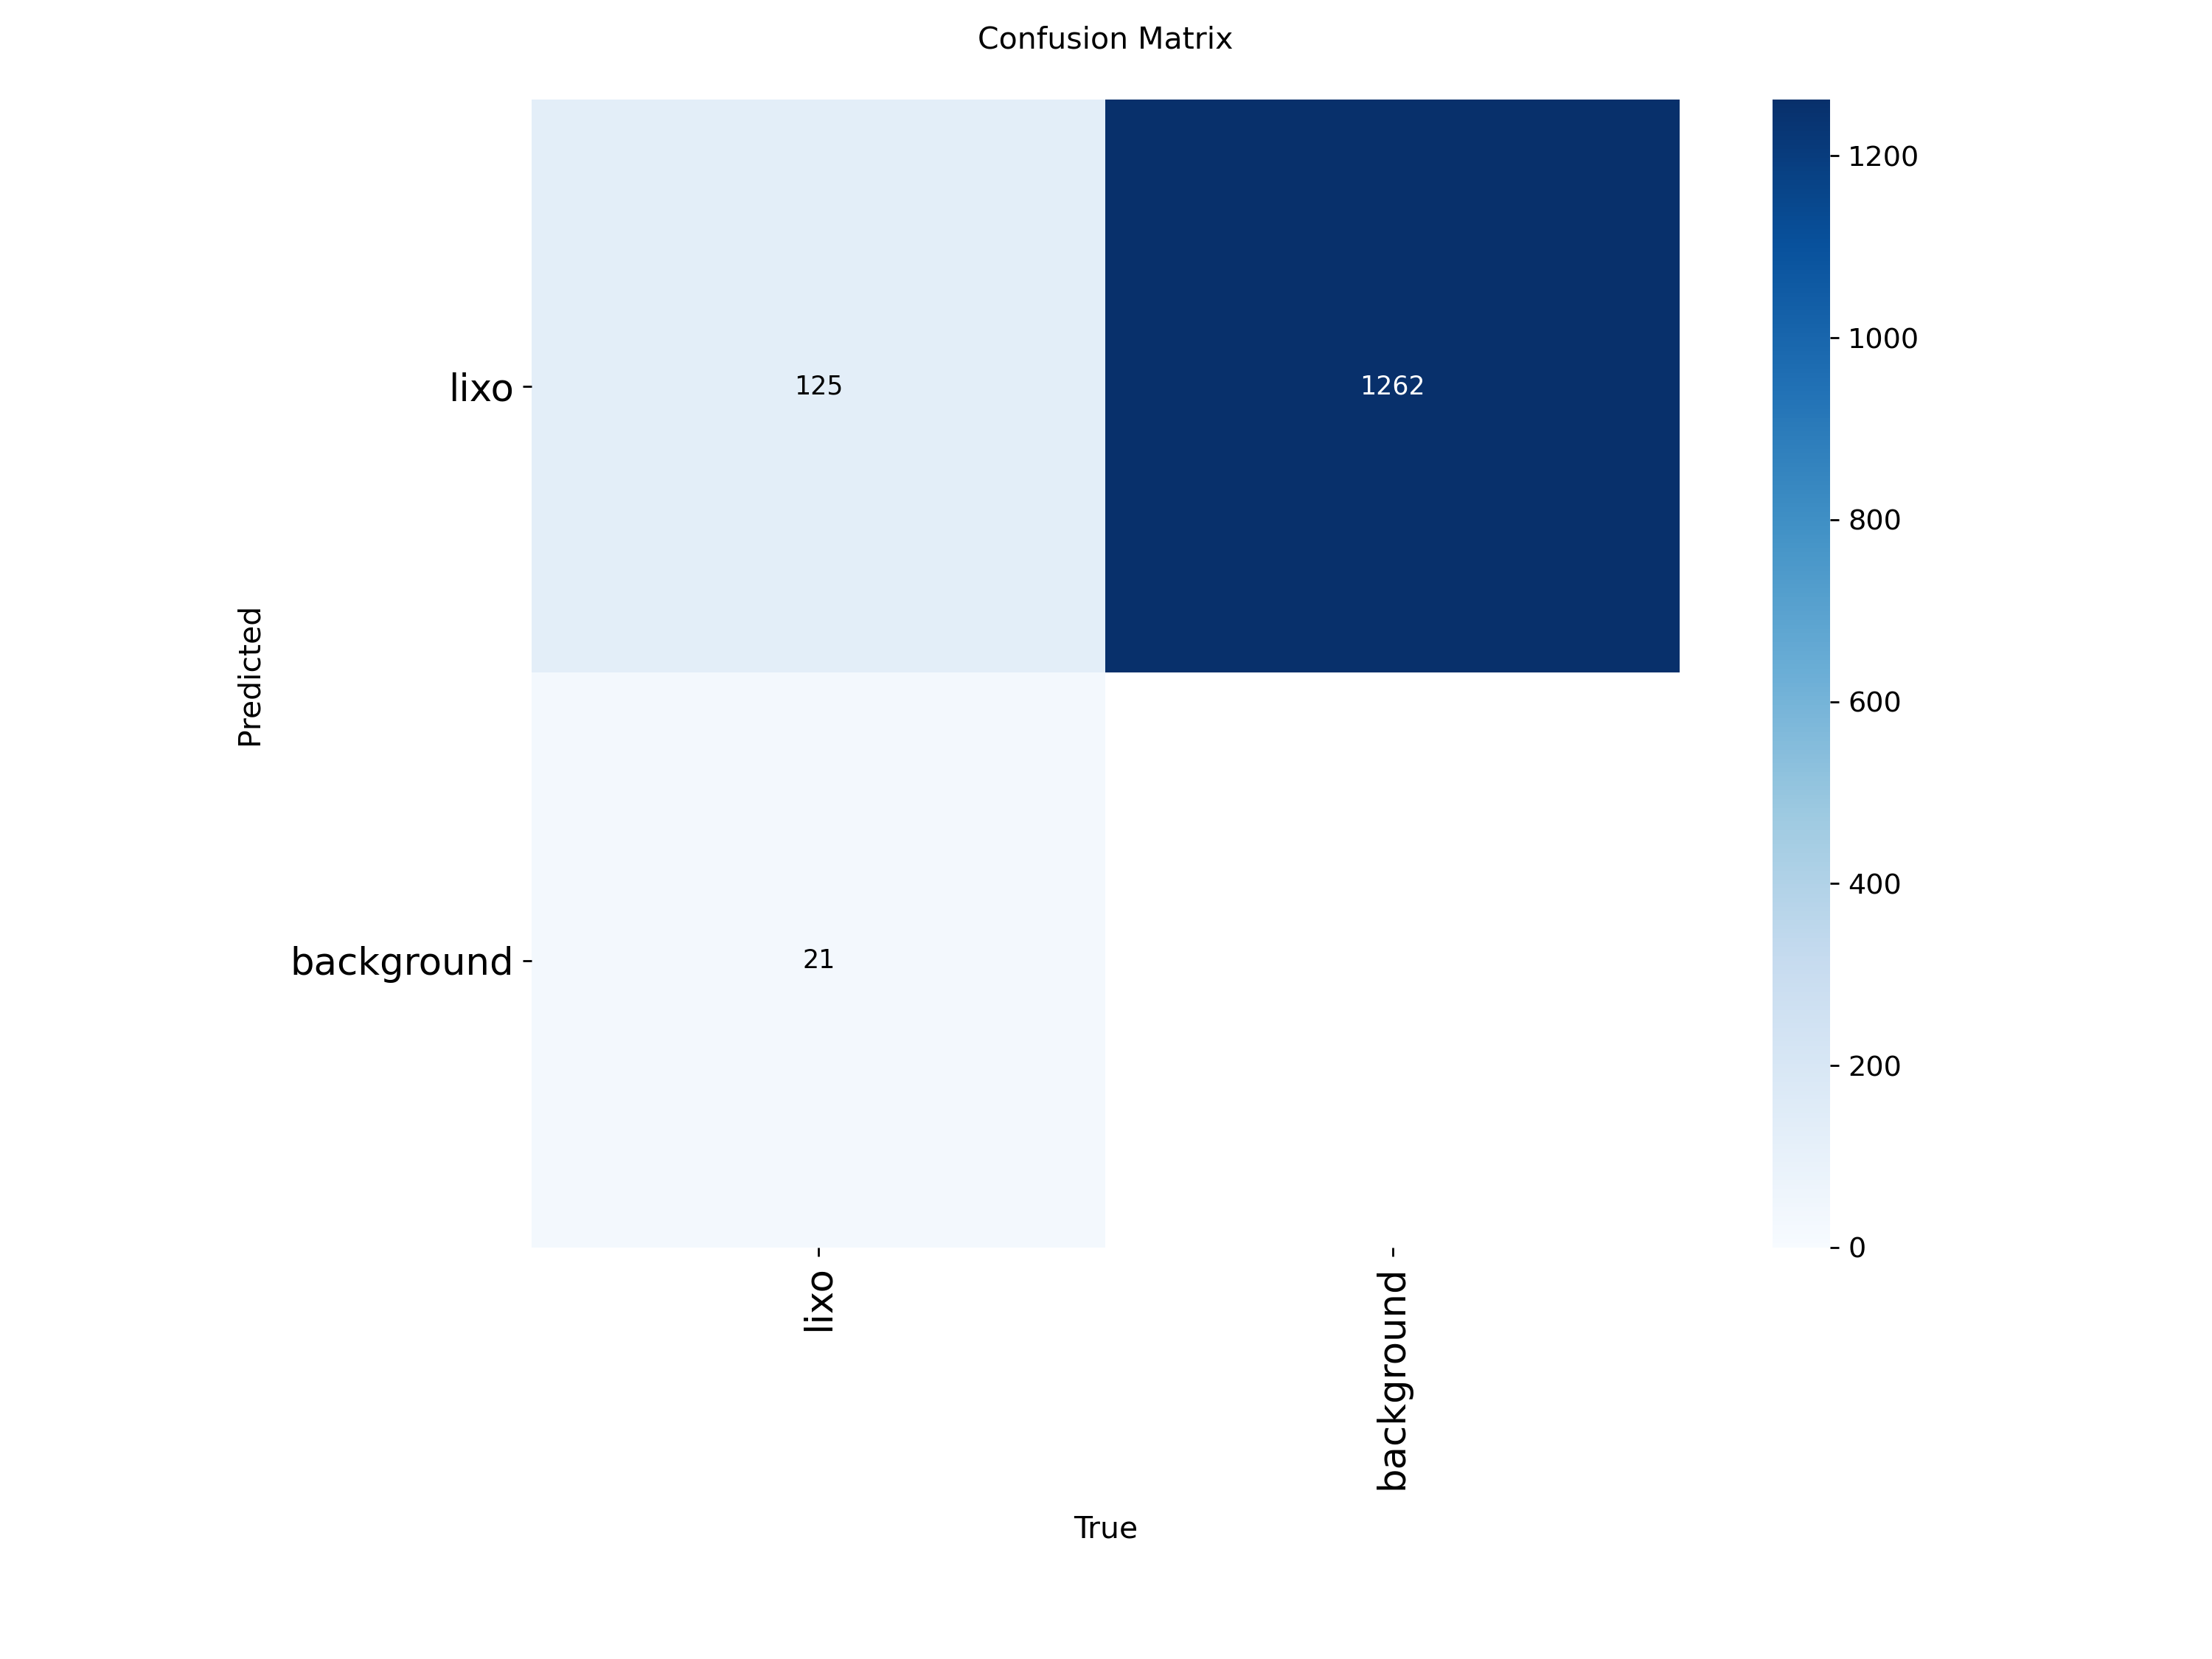

Matriz de confusao normalizada: lixo


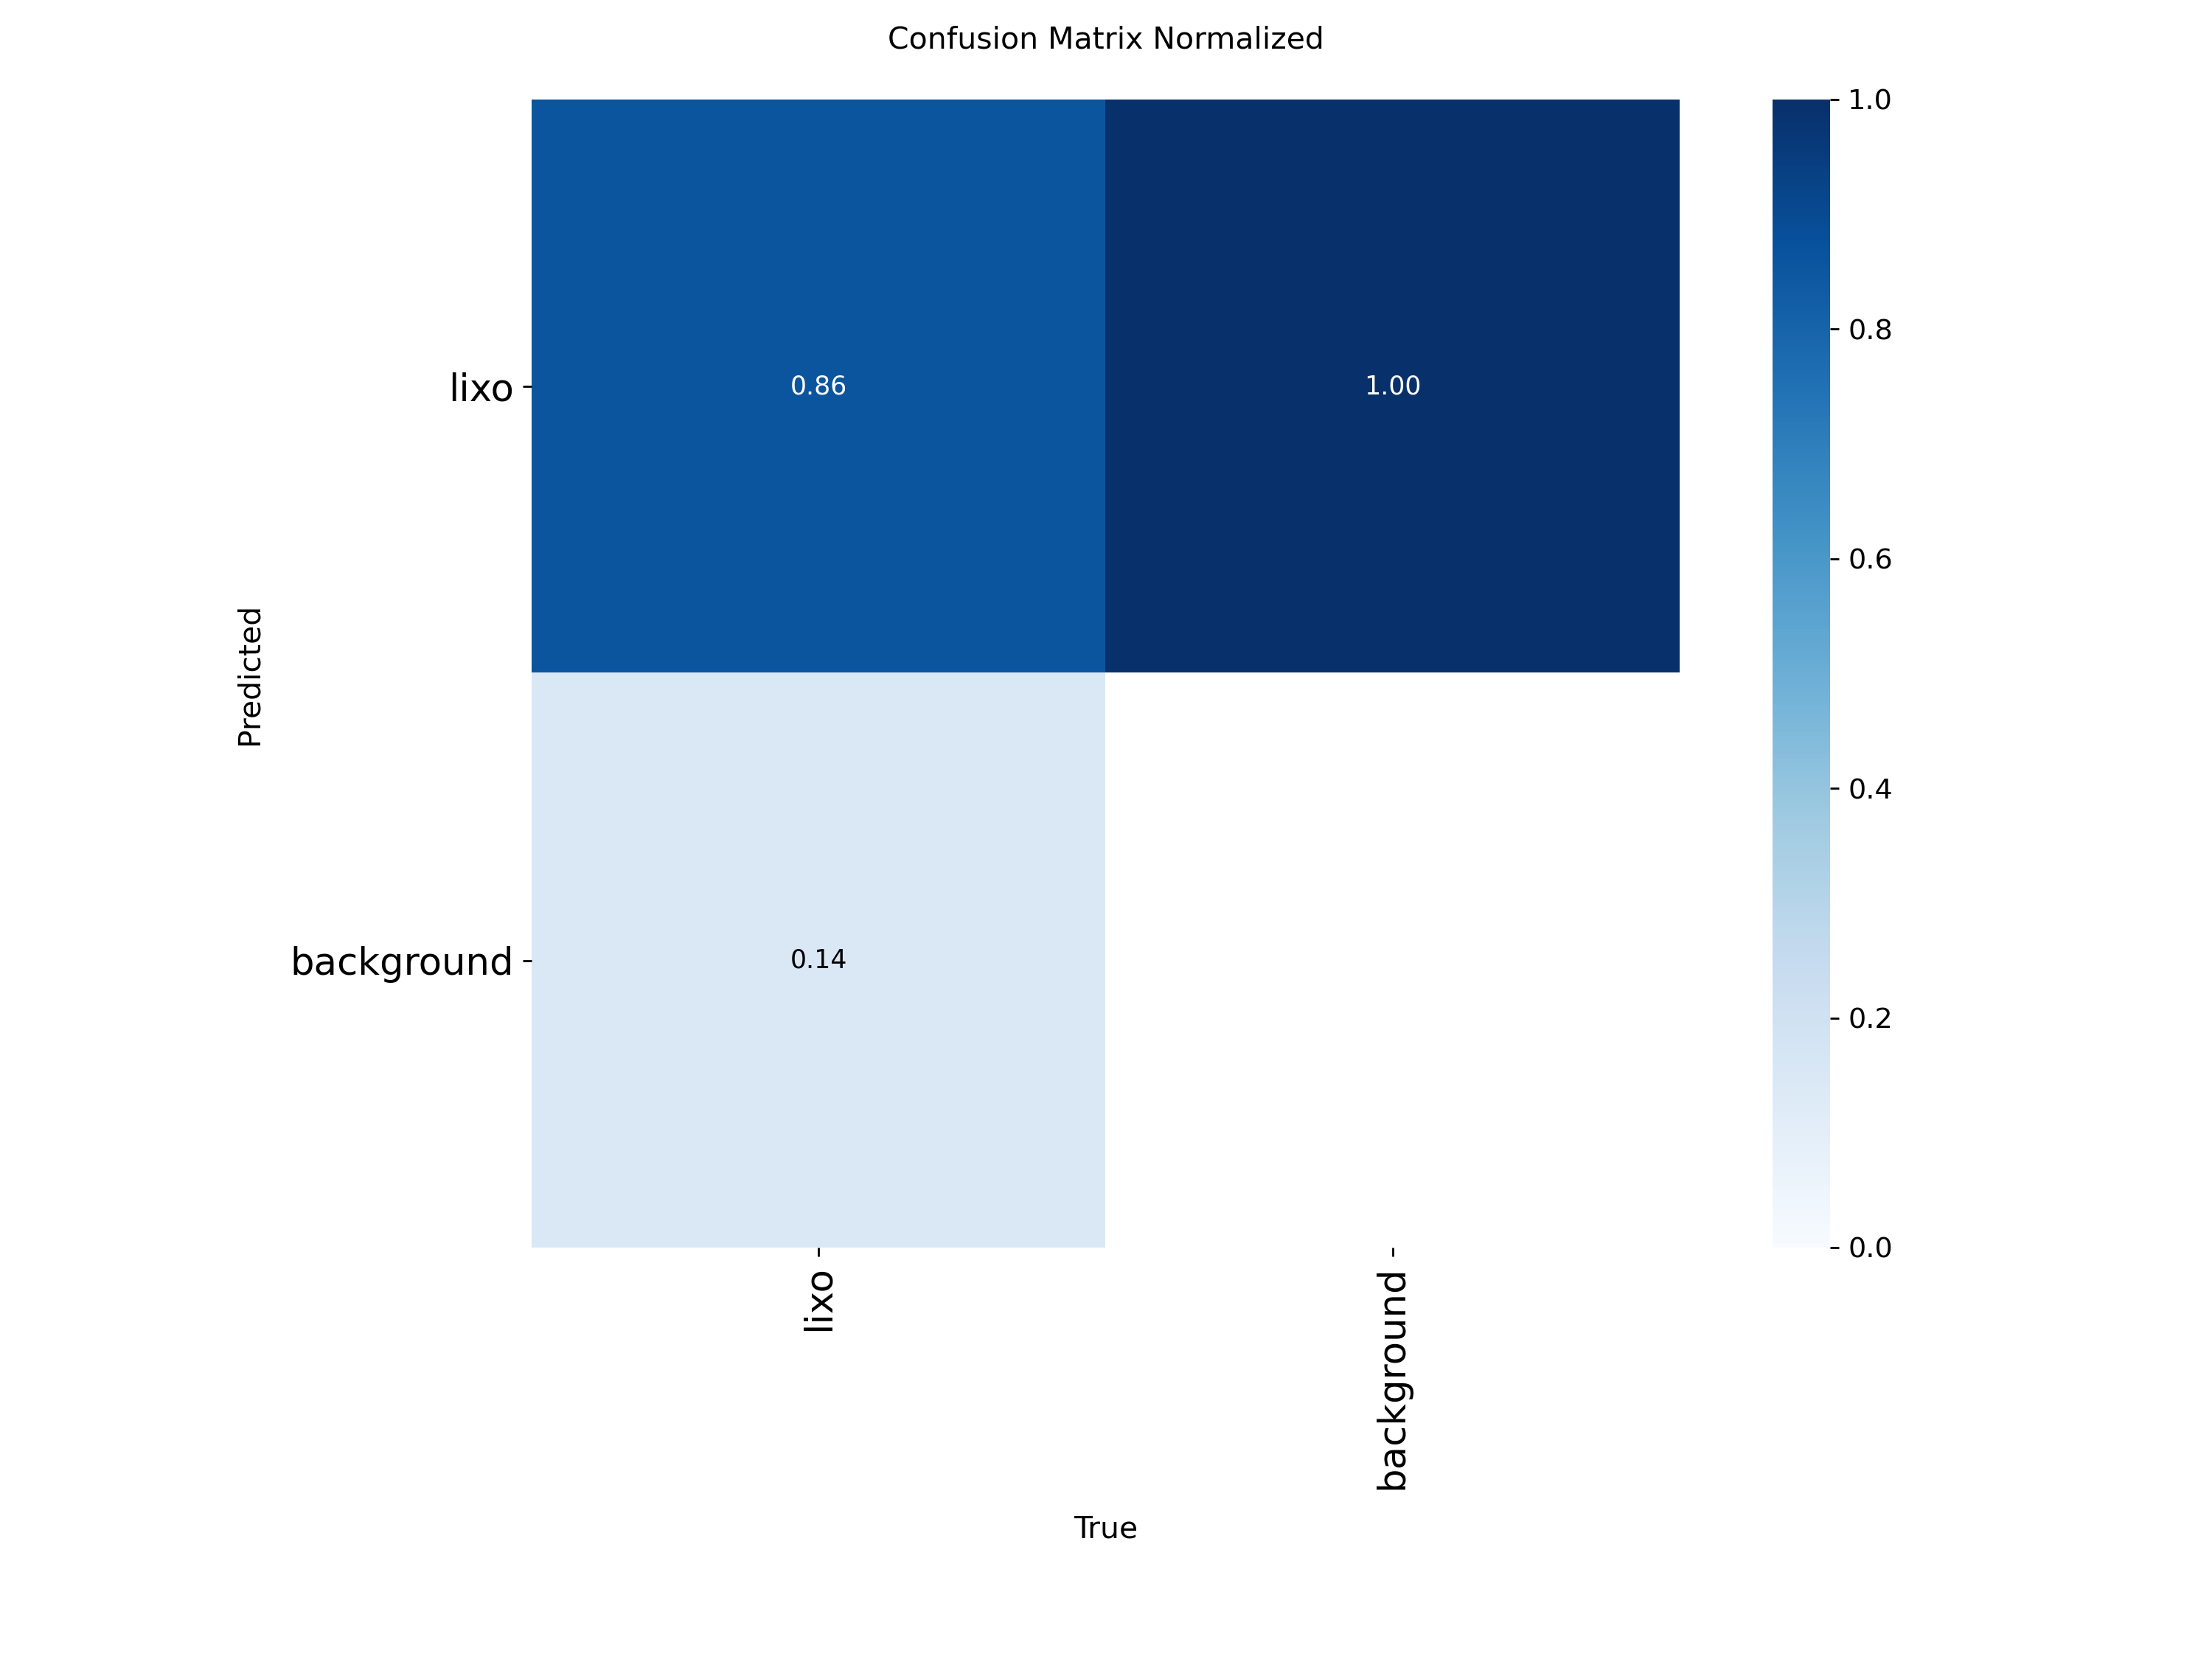

Classe unica: lixo
Instancias anotadas na validacao: 146
Matrizes salvas em: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 02\runs\segment\teste02_dataset_model-2\matriz_confusao_best\lixo_unica_classe


In [5]:
from collections import Counter
from pathlib import Path

import yaml
from IPython.display import display
from PIL import Image as PILImage
from ultralytics import YOLO

PASTA_PROJETO = Path.cwd()
PASTA_EXECUCAO = PASTA_PROJETO / "runs" / "segment" / "teste02_dataset_model-2"
ARQUIVO_BEST = PASTA_EXECUCAO / "weights" / "best.pt"
ARQUIVO_DATASET = PASTA_PROJETO / "dataset_model_yolo" / "dataset.yaml"
PASTA_DATASET_YOLO = ARQUIVO_DATASET.parent
for caminho in (ARQUIVO_BEST, ARQUIVO_DATASET):
    if not caminho.is_file():
        raise FileNotFoundError(f"Artefato necessario nao encontrado: {caminho}")

configuracao_dataset = yaml.safe_load(ARQUIVO_DATASET.read_text(encoding="utf-8"))
nome_classes = configuracao_dataset.get("names", {})
if isinstance(nome_classes, list):
    nome_classes = {indice: nome for indice, nome in enumerate(nome_classes)}
else:
    nome_classes = {int(indice): nome for indice, nome in nome_classes.items()}

if nome_classes != {0: "lixo"}:
    raise ValueError(f"Esperada uma unica classe 'lixo'; configuracao atual: {nome_classes}")

rotulos_validacao = PASTA_DATASET_YOLO / "labels" / "val"
instancias_por_classe = Counter()
for arquivo_rotulo in rotulos_validacao.glob("*.txt"):
    for linha in arquivo_rotulo.read_text(encoding="utf-8").splitlines():
        if linha.strip():
            instancias_por_classe[int(linha.split(maxsplit=1)[0])] += 1

if set(instancias_por_classe) - {0}:
    raise ValueError(f"Foram encontrados IDs de classe diferentes de 0: {instancias_por_classe}")

PASTA_SAIDA_MATRIZ = PASTA_EXECUCAO / "matriz_confusao_best"
modelo_matriz = YOLO(str(ARQUIVO_BEST))
metricas_matriz = modelo_matriz.val(
    data=str(ARQUIVO_DATASET),
    split="val",
    imgsz=512,
    batch=4,
    device="cpu",
    plots=True,
    verbose=False,
    workers=0,
    project=str(PASTA_SAIDA_MATRIZ),
    name="lixo_unica_classe",
    exist_ok=True,
)

PASTA_RESULTADO_MATRIZ = PASTA_SAIDA_MATRIZ / "lixo_unica_classe"
arquivo_matriz = PASTA_RESULTADO_MATRIZ / "confusion_matrix.png"
arquivo_matriz_normalizada = PASTA_RESULTADO_MATRIZ / "confusion_matrix_normalized.png"
for caminho, titulo in (
    (arquivo_matriz, "Matriz de confusao: lixo"),
    (arquivo_matriz_normalizada, "Matriz de confusao normalizada: lixo"),
):
    if not caminho.is_file():
        raise FileNotFoundError(f"A matriz nao foi gerada: {caminho}")
    print(titulo)
    display(PILImage.open(caminho))

print(f"Classe unica: {nome_classes[0]}")
print(f"Instancias anotadas na validacao: {instancias_por_classe[0]}")
print(f"Matrizes salvas em: {PASTA_RESULTADO_MATRIZ}")